# 3 · Which method works best?
**Protocol:** hide 30% of existing connections at random. Each model only sees the remaining 70%
(so mutual friends can't cheat), recommends top-5 for every user with a hidden connection, and we
check how many hidden friends come back. Averaged over 5 random splits (seeds 1–5).
α for the hybrid is tuned on a separate split (seed 0).

Metrics: Precision@5, Recall@5, nDCG@5 (rank-aware, main metric), MRR@5, and coverage (share of users who ever get recommended).

In [1]:
import pandas as pd
from recsys import db
from recsys.models import Recommender, DEFAULT_WEIGHTS
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)

import matplotlib.pyplot as plt
from recsys.evaluate import compare, tune_alpha
conn = db.connect(db.DEFAULT_DB) if db.DEFAULT_DB.exists() else db.connect(db.build_db())
profiles, conns, signals = db.load_profiles(conn), db.load_connections(conn), db.load_signals(conn)

### Tune α (hybrid weight on TF-IDF) on the validation split

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'sentence-transformers/all-MiniLM-L6-v2'.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

best α = 0.0


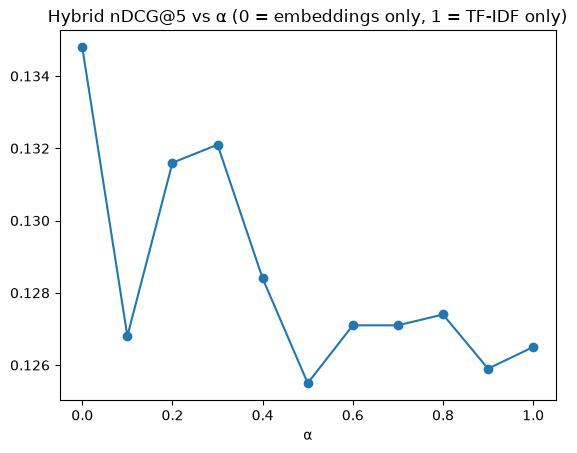

In [2]:
alphas = tune_alpha(profiles, conns)
best_alpha = float(alphas.idxmax())
ax = alphas.plot(marker="o", title="Hybrid nDCG@5 vs α (0 = embeddings only, 1 = TF-IDF only)"); ax.set_xlabel("α")
print("best α =", best_alpha)

### Interest-only methods

In [3]:
base = compare({
    "random":    lambda: Recommender("random"),
    "jaccard":   lambda: Recommender("jaccard"),
    "tfidf":     lambda: Recommender("tfidf"),
    "embedding": lambda: Recommender("embedding"),
    "hybrid":    lambda: Recommender("hybrid", alpha=best_alpha),
}, profiles, conns)
base

,precision@k,recall@k,ndcg@k,mrr@k,coverage
jaccard,0.0902,0.1824,0.1415,0.1888,0.985
hybrid,0.0895,0.1751,0.1314,0.1763,0.938
embedding,0.0895,0.1751,0.1314,0.1763,0.938
tfidf,0.0858,0.1732,0.1284,0.1683,0.978
random,0.0126,0.0242,0.0197,0.0279,0.999


### Tune the re-rank weights (validation split, seed 0)
Bigger weights score a bit higher here, but then mutual friends/places outrank interests. Defaults (0.3, 0.3, 0.05)
keep interests primary while capturing most of the gain.

In [4]:
import itertools
from recsys.evaluate import evaluate
grid = []
for m, pl, r in itertools.product([0.1, 0.2, 0.3, 0.5], [0.05, 0.1, 0.2, 0.3], [0, 0.05]):
    w = {"mutual": m, "place": pl, "recency": r}
    grid.append({**w, "ndcg@k": evaluate(lambda: Recommender("hybrid", alpha=best_alpha, weights=w), profiles, conns, signals, seeds=[0])["ndcg@k"]})
pd.DataFrame(grid).sort_values("ndcg@k", ascending=False).head(8)

,mutual,place,recency,ndcg@k
30,0.5,0.3,0.00,0.2407
31,0.5,0.3,0.05,0.2348
28,0.5,0.2,0.00,0.2339
29,0.5,0.2,0.05,0.2322
20,0.3,0.2,0.00,0.2302
26,0.5,0.1,0.00,0.2285
21,0.3,0.2,0.05,0.2281
23,0.3,0.3,0.05,0.2274


### Ablation: adding the secondary signals to the hybrid, one at a time

In [5]:
W = DEFAULT_WEIGHTS
ablation = compare({
    "hybrid (interests only)": lambda: Recommender("hybrid", alpha=best_alpha),
    "+ recency":               lambda: Recommender("hybrid", alpha=best_alpha, weights={"recency": W["recency"]}),
    "+ places":                lambda: Recommender("hybrid", alpha=best_alpha, weights={"place": W["place"]}),
    "+ mutual friends":        lambda: Recommender("hybrid", alpha=best_alpha, weights={"mutual": W["mutual"]}),
    "+ all signals":           lambda: Recommender("hybrid", alpha=best_alpha, weights=W),
    "tfidf + all signals":     lambda: Recommender("tfidf", weights=W),
}, profiles, conns, signals)
ablation

,precision@k,recall@k,ndcg@k,mrr@k,coverage
+ all signals,0.1273,0.2619,0.2110,0.2771,0.895
+ mutual friends,0.1161,0.2425,0.1978,0.2649,0.955
tfidf + all signals,0.1162,0.2313,0.1840,0.2452,0.961
+ places,0.1056,0.2116,0.1664,0.2280,0.896
+ recency,0.0923,0.1832,0.1372,0.1814,0.936
hybrid (interests only),0.0895,0.1751,0.1314,0.1763,0.938


Winner: + all signals


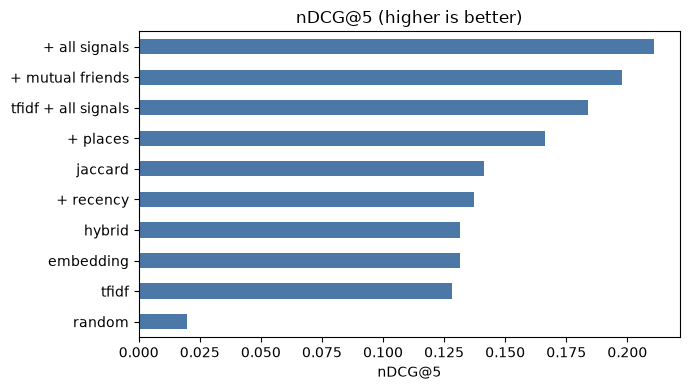

In [6]:
results = pd.concat([base, ablation.drop(index="hybrid (interests only)")])
ax = results["ndcg@k"].sort_values().plot.barh(figsize=(7, 4), color="#4C78A8", title="nDCG@5 (higher is better)")
ax.set_xlabel("nDCG@5"); plt.tight_layout()
print("Winner:", results["ndcg@k"].idxmax())